In [26]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

df = pd.read_csv('default of credit card clients.csv')
df = df.rename(columns={'dpnm': 'default'}).drop(columns='ID')
print(df.shape)
df.head()

(30000, 24)


,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_1,PAY_2,PAY_3,PAY_4,PAY_5,...,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6,default
0,20000,2,2,1,24,2,2,-1,-1,-2,...,0,0,0,0,689,0,0,0,0,1
1,120000,2,2,2,26,-1,2,0,0,0,...,3272,3455,3261,0,1000,1000,1000,0,2000,1
2,90000,2,2,2,34,0,0,0,0,0,...,14331,14948,15549,1518,1500,1000,1000,1000,5000,0
3,50000,2,2,1,37,0,0,0,0,0,...,28314,28959,29547,2000,2019,1200,1100,1069,1000,0
4,50000,1,2,1,57,-1,0,-1,0,0,...,20940,19146,19131,2000,36681,10000,9000,689,679,0


In [27]:
df.info()
df.describe().T

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 30000 entries, 0 to 29999
Data columns (total 24 columns):
 #   Column     Non-Null Count  Dtype
---  ------     --------------  -----
 0   LIMIT_BAL  30000 non-null  int64
 1   SEX        30000 non-null  int64
 2   EDUCATION  30000 non-null  int64
 3   MARRIAGE   30000 non-null  int64
 4   AGE        30000 non-null  int64
 5   PAY_1      30000 non-null  int64
 6   PAY_2      30000 non-null  int64
 7   PAY_3      30000 non-null  int64
 8   PAY_4      30000 non-null  int64
 9   PAY_5      30000 non-null  int64
 10  PAY_6      30000 non-null  int64
 11  BILL_AMT1  30000 non-null  int64
 12  BILL_AMT2  30000 non-null  int64
 13  BILL_AMT3  30000 non-null  int64
 14  BILL_AMT4  30000 non-null  int64
 15  BILL_AMT5  30000 non-null  int64
 16  BILL_AMT6  30000 non-null  int64
 17  PAY_AMT1   30000 non-null  int64
 18  PAY_AMT2   30000 non-null  int64
 19  PAY_AMT3   30000 non-null  int64
 20  PAY_AMT4   30000 non-null  int64
 21  PAY_AMT5   3

,count,mean,std,min,25%,50%,75%,max
LIMIT_BAL,30000.0,167484.322667,129747.661567,10000.0,50000.00,140000.0,240000.00,1000000.0
SEX,30000.0,1.603733,0.489129,1.0,1.00,2.0,2.00,2.0
EDUCATION,30000.0,1.853133,0.790349,0.0,1.00,2.0,2.00,6.0
MARRIAGE,30000.0,1.551867,0.521970,0.0,1.00,2.0,2.00,3.0
AGE,30000.0,35.485500,9.217904,21.0,28.00,34.0,41.00,79.0
PAY_1,30000.0,-0.016700,1.123802,-2.0,-1.00,0.0,0.00,8.0
PAY_2,30000.0,-0.133767,1.197186,-2.0,-1.00,0.0,0.00,8.0
PAY_3,30000.0,-0.166200,1.196868,-2.0,-1.00,0.0,0.00,8.0
PAY_4,30000.0,-0.220667,1.169139,-2.0,-1.00,0.0,0.00,8.0
PAY_5,30000.0,-0.266200,1.133187,-2.0,-1.00,0.0,0.00,8.0


In [28]:
print('Missing values:', df.isnull().sum().sum())
print('Duplicate rows:', df.duplicated().sum())
df = df.drop_duplicates().reset_index(drop=True)
df['EDUCATION'] = df['EDUCATION'].replace({0: 4, 5: 4, 6: 4})
df['MARRIAGE'] = df['MARRIAGE'].replace({0: 3})
print(df.shape)


Missing values: 0
Duplicate rows: 35
(29965, 24)


default
0    23335
1     6630
Name: count, dtype: int64
default
0    0.779
1    0.221
Name: proportion, dtype: float64


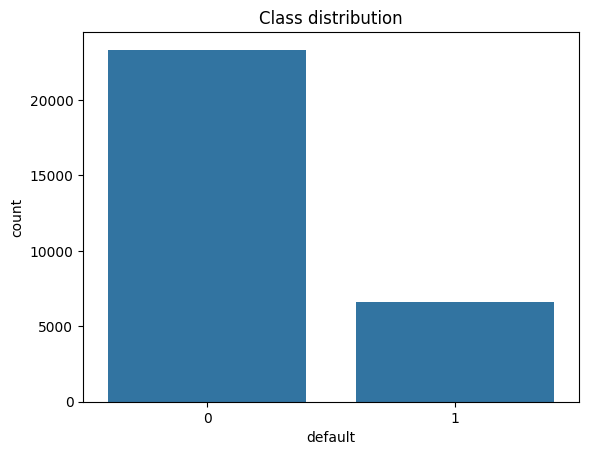

In [29]:
print(df['default'].value_counts())
print(df['default'].value_counts(normalize=True).round(3))
sns.countplot(x='default', data=df)
plt.title('Class distribution')
plt.show()

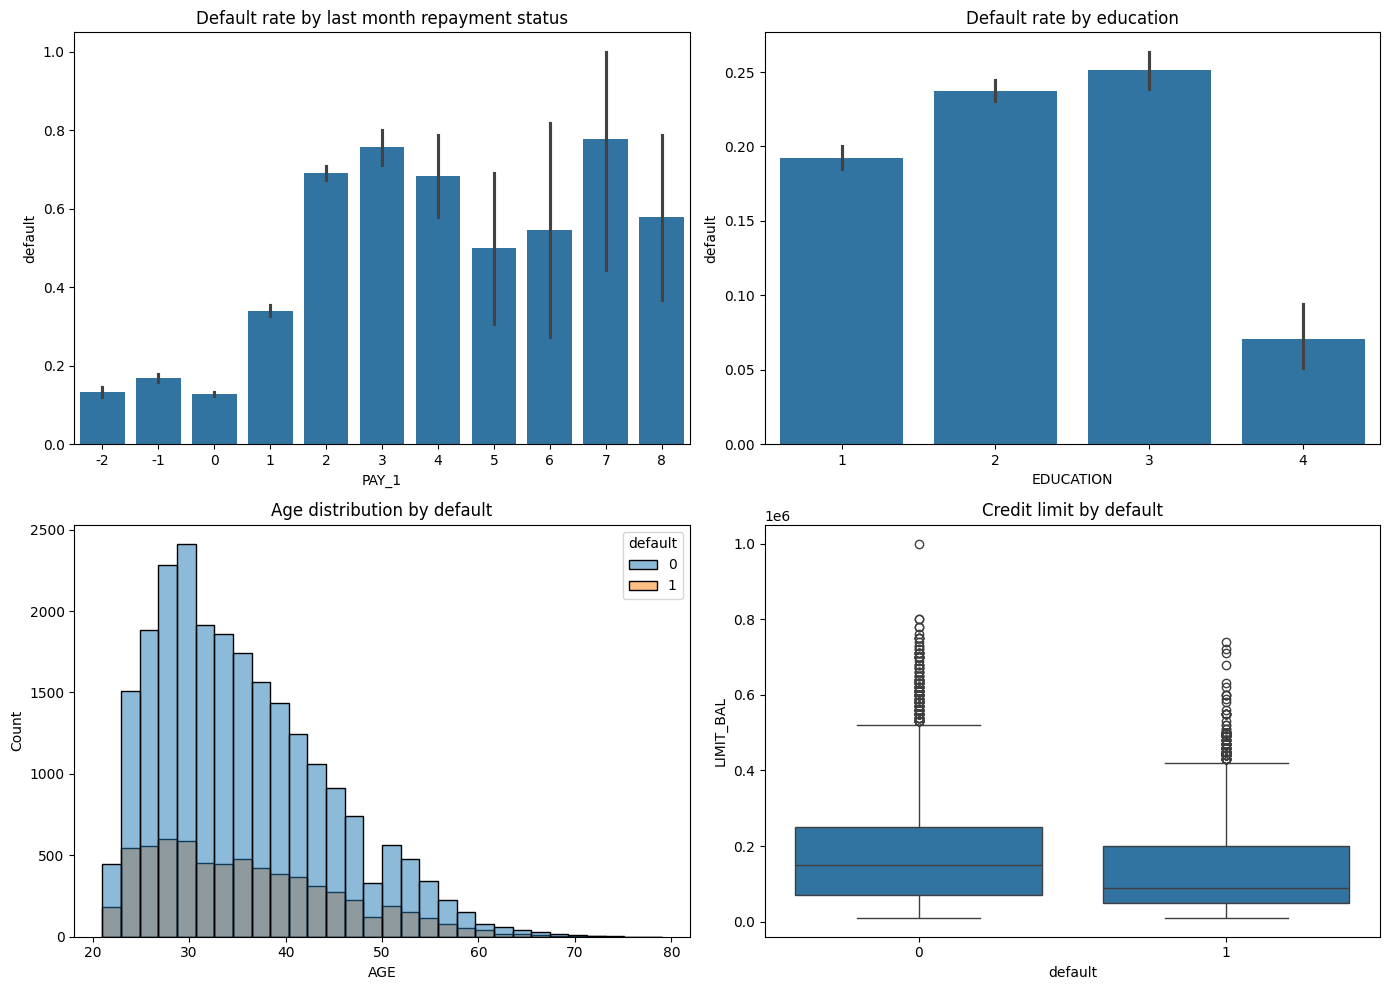

In [30]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
sns.barplot(x='PAY_1', y='default', data=df, ax=axes[0, 0])
axes[0, 0].set_title('Default rate by last month repayment status')
sns.barplot(x='EDUCATION', y='default', data=df, ax=axes[0, 1])
axes[0, 1].set_title('Default rate by education')
sns.histplot(data=df, x='AGE', hue='default', bins=30, ax=axes[1, 0])
axes[1, 0].set_title('Age distribution by default')
sns.boxplot(x='default', y='LIMIT_BAL', data=df, ax=axes[1, 1])
axes[1, 1].set_title('Credit limit by default')
plt.tight_layout()
plt.show()

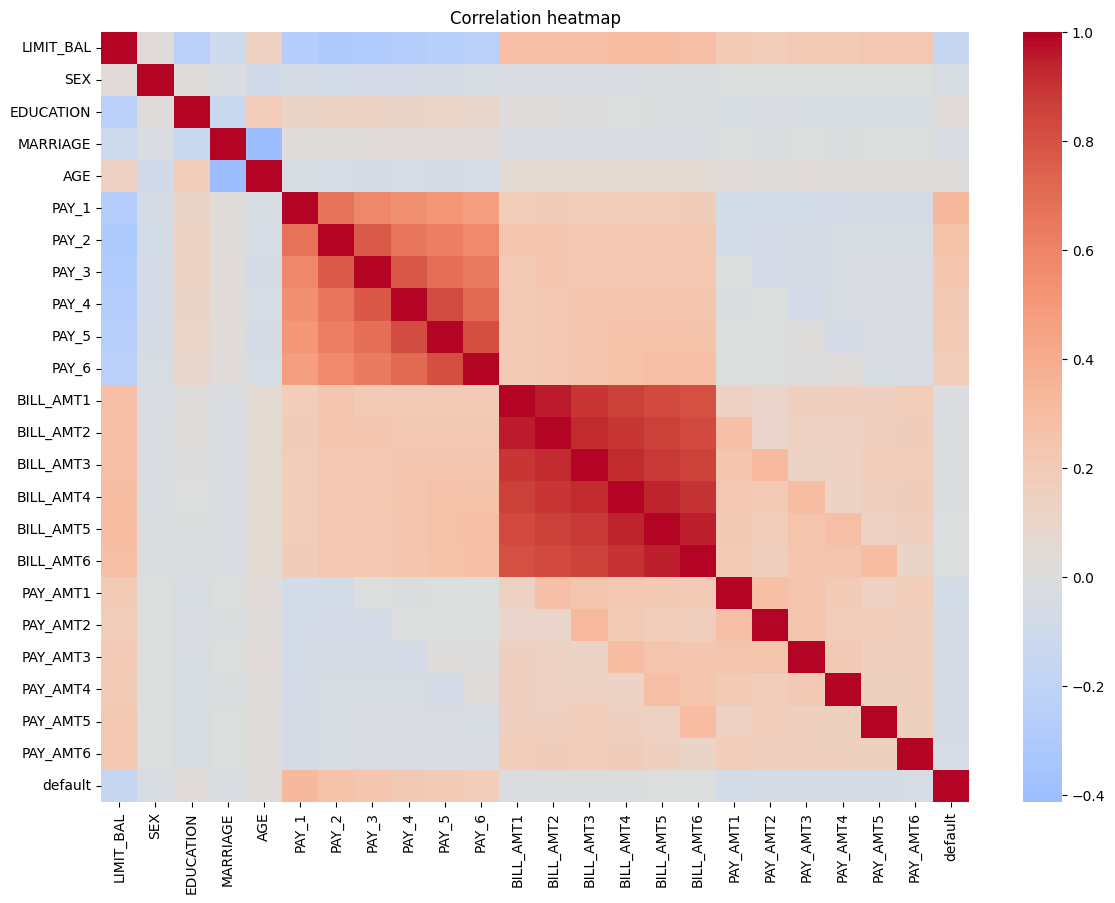

,default
PAY_1,0.325
PAY_2,0.264
PAY_3,0.235
PAY_4,0.217
PAY_5,0.204
PAY_6,0.187
EDUCATION,0.034
AGE,0.014
BILL_AMT6,-0.005
BILL_AMT5,-0.007


In [31]:
plt.figure(figsize=(14, 10))
sns.heatmap(df.corr(), cmap='coolwarm', center=0)
plt.title('Correlation heatmap')
plt.show()
df.corr()['default'].drop('default').sort_values(ascending=False).round(3)

In [32]:
df['AVG_BILL'] = df[[f'BILL_AMT{i}' for i in range(1, 7)]].mean(axis=1)
df['AVG_PAY'] = df[[f'PAY_AMT{i}' for i in range(1, 7)]].mean(axis=1)

FEATURES = ['LIMIT_BAL', 'SEX', 'EDUCATION', 'MARRIAGE', 'AGE',
            'PAY_1', 'PAY_2', 'PAY_3', 'AVG_BILL', 'AVG_PAY']

X = df[FEATURES]
y = df['default']

from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42)
print(X_train.shape, X_test.shape)

(23972, 10) (5993, 10)


In [33]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier

models = {
    'Logistic Regression': make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000, class_weight='balanced', random_state=42)),
    'Decision Tree': DecisionTreeClassifier(max_depth=5, class_weight='balanced', random_state=42),
    'Random Forest': RandomForestClassifier(n_estimators=300, max_depth=10, min_samples_leaf=5, class_weight='balanced', random_state=42, n_jobs=-1),
    'KNN': make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=25)),
}

for name, model in models.items():
    model.fit(X_train, y_train)
    print(name, 'trained')

Logistic Regression trained
Decision Tree trained
Random Forest trained
KNN trained


In [34]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score

rows = []
for name, model in models.items():
    pred = model.predict(X_test)
    prob = model.predict_proba(X_test)[:, 1]
    rows.append({
        'Model': name,
        'Accuracy': accuracy_score(y_test, pred),
        'Precision': precision_score(y_test, pred),
        'Recall': recall_score(y_test, pred),
        'F1': f1_score(y_test, pred),
        'ROC-AUC': roc_auc_score(y_test, prob),
    })

results = pd.DataFrame(rows).set_index('Model').round(3)
results.sort_values('ROC-AUC', ascending=False)

,Accuracy,Precision,Recall,F1,ROC-AUC
Model,,,,,
Random Forest,0.781,0.506,0.548,0.526,0.766
Decision Tree,0.723,0.414,0.606,0.492,0.747
KNN,0.813,0.645,0.348,0.452,0.738
Logistic Regression,0.683,0.371,0.622,0.465,0.716


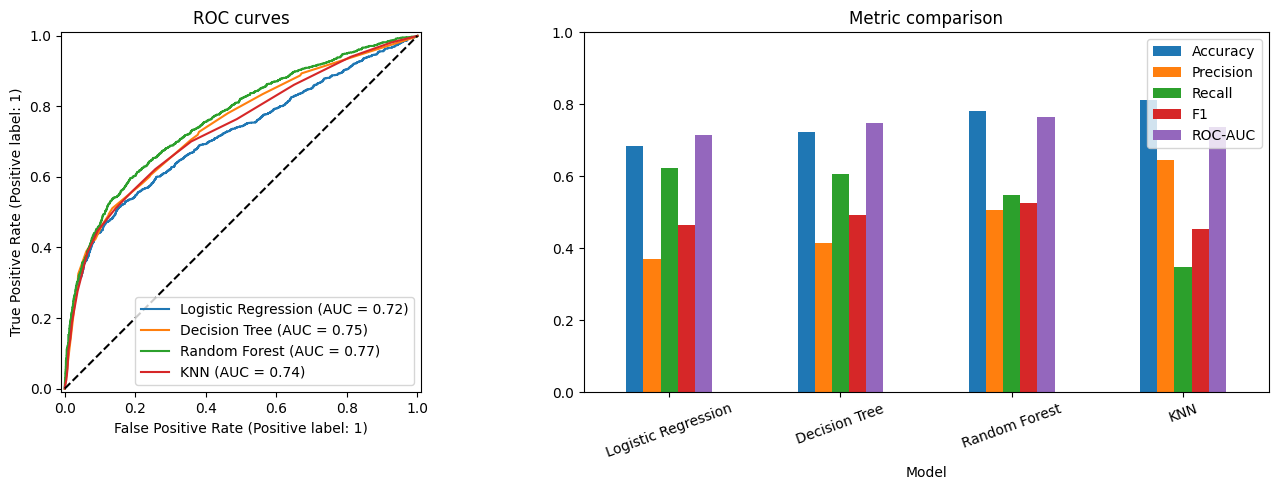

In [35]:
from sklearn.metrics import RocCurveDisplay, ConfusionMatrixDisplay

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for name, model in models.items():
    RocCurveDisplay.from_estimator(model, X_test, y_test, name=name, ax=axes[0])
axes[0].plot([0, 1], [0, 1], 'k--')
axes[0].set_title('ROC curves')
results[['Accuracy', 'Precision', 'Recall', 'F1', 'ROC-AUC']].plot(kind='bar', ax=axes[1])
axes[1].set_title('Metric comparison')
axes[1].set_ylim(0, 1)
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

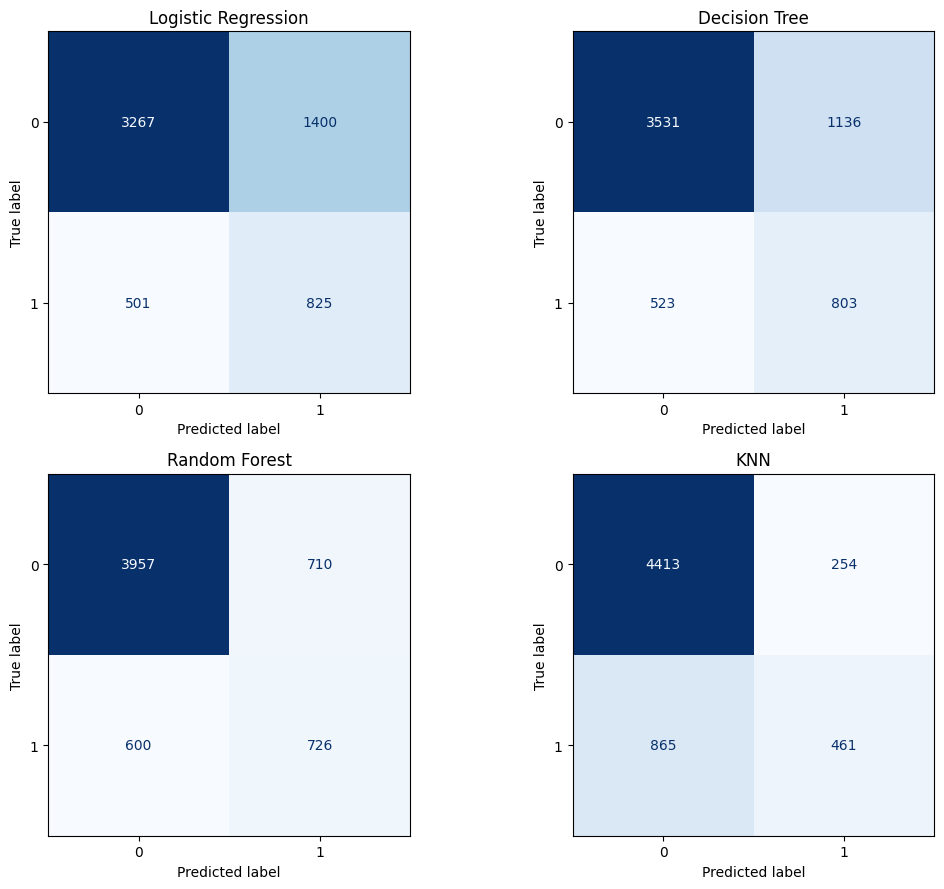

In [36]:
fig, axes = plt.subplots(2, 2, figsize=(11, 9))
for ax, (name, model) in zip(axes.ravel(), models.items()):
    ConfusionMatrixDisplay.from_estimator(model, X_test, y_test, ax=ax, cmap='Blues', colorbar=False)
    ax.set_title(name)
plt.tight_layout()
plt.show()

Best model by ROC-AUC: Random Forest
              precision    recall  f1-score   support

  No default       0.87      0.85      0.86      4667
     Default       0.51      0.55      0.53      1326

    accuracy                           0.78      5993
   macro avg       0.69      0.70      0.69      5993
weighted avg       0.79      0.78      0.78      5993



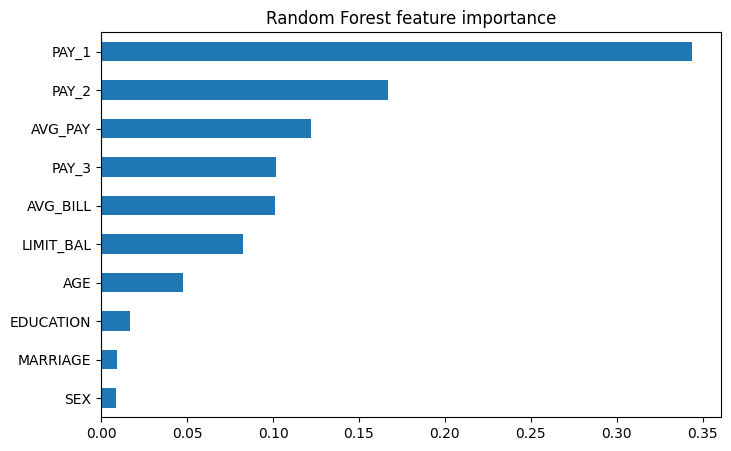

In [37]:
best_name = results['ROC-AUC'].idxmax()
best_model = models[best_name]
print('Best model by ROC-AUC:', best_name)

from sklearn.metrics import classification_report
print(classification_report(y_test, best_model.predict(X_test), target_names=['No default', 'Default']))

rf = models['Random Forest']
importance = pd.Series(rf.feature_importances_, index=FEATURES).sort_values()
importance.plot(kind='barh', figsize=(8, 5))
plt.title('Random Forest feature importance')
plt.show()

In [38]:
import joblib
joblib.dump(best_model, 'model.joblib')
from google.colab import files
files.download('model.joblib')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [39]:
import sklearn
print(sklearn.__version__)

1.6.1
